# Time Split, Baselines and Feature Engineering

## Overview :-

**What this notebook does :**
- splits the weeks by **date** into train, validation and test
- builds the two simplest forecasts (**baselines**) and scores them. Their score is the target for every later model
- builds the **feature table** the machine learning models learn from

**Approach followed :**
- time based split, never a random split
- RMSSE as the main score : the error divided by the product's own normal weekly change

**Steps :**
- 1 . Import Required Modules
- 2 . Settings
- 3 . Data Reading
- 4 . Time Based Split
- 5 . Baseline Models
- 6 . Evaluation
- 7 . Feature Engineering

**Reads / Writes :**
- **Reads :** `data/prepared/weekly_sales.parquet`
- **Writes :** `data/prepared/features.parquet`, the feature table for the models

# 1 . Import Required Modules :-

In [1]:
## import the libraries used in this notebook
import numpy as np                          # import numpy library for numerical calculation
import pandas as pd                         # import pandas library for reading the data
import matplotlib.pyplot as plt             # import matplotlib library for plotting graphs
import seaborn as sns                       # import seaborn library for data visualisation
%matplotlib inline

import warnings                             # import warnings to ignore future warnings
warnings.filterwarnings('ignore')

# 2 . Settings :-

- **DATA_DIR :** folder with the prepared dataset, the feature table is saved here too

In [2]:
## folder of the prepared data
DATA_DIR = '../data/prepared/'                                            # prepared data folder

# 3 . Data Reading :-

In [3]:
## read the dataset and turn it into one row per product and one column per week
full_data = pd.read_parquet(DATA_DIR + 'weekly_sales.parquet')            # weekly sales of the 100 products

data = full_data.pivot(index='item_id', columns='week', values='sales').sort_index().astype(float)
weeks = data.columns                                                      # all weeks in order
items = data.index                                                        # all products in order
first_sale_date = full_data.groupby('item_id')['first_sale_date'].first().loc[items]   # first sale date of each product

print("Products x weeks : ", data.shape)

Products x weeks :  (100, 176)


### Insights :-
- The sales are now one row per product and one column per week : **100** products x **176** weeks.

# 4 . Time Based Split :-

## ( i ) . Why not a Random Split :-

`train_test_split` picks random rows for testing. Here the rows are weeks of the same products, so a random split would train on later weeks and test on earlier weeks, i.e. use the future to predict the past. The score would look good but it would be false.

So the data is split by **date**. On each **forecast date** (a Sunday) a model may use only the weeks up to that date, and it forecasts the next **4** weeks.

## ( ii ) . Forecast Dates :-

- **H :** **4** weeks are forecast on each date, the weeks a store plans its orders for.
- **Train :** on every forecast date, a model learns only from the weeks up to that date.
- **VALID_DATES (validation) :** **4** dates, starting at **18 Oct 2015**, the date the products were chosen and where the EDA stopped. They are **4** weeks apart, so their forecast weeks do not overlap. Models are compared and tuned on these dates, as often as needed. Using 4 dates instead of 1 shows whether a model is better every time or only by luck.
- **TEST_DATE (test) :** **24 Apr 2016**. Its 4 forecast weeks (1 May to 22 May 2016) are the last 4 weeks of the data. They are used **only once**, at the end, for the chosen model.

In [4]:
## the forecast dates, with the weeks known and the weeks forecast on each date
H = 4                                                                     # weeks to forecast
VALID_DATES = pd.to_datetime(['2015-10-18', '2015-11-15', '2015-12-13', '2016-01-10'])
TEST_DATE = pd.Timestamp('2016-04-24')

split = pd.DataFrame({'forecast_date': list(VALID_DATES) + [TEST_DATE]})
split['role'] = ['validation'] * len(VALID_DATES) + ['test']
split['training_weeks'] = [weeks.get_loc(i) + 1 for i in split['forecast_date']]      # weeks known on the forecast date
split['first_forecast_week'] = split['forecast_date'] + pd.Timedelta(weeks=1)         # week ending 1 week later
split['last_forecast_week'] = split['forecast_date'] + pd.Timedelta(weeks=H)          # week ending 4 weeks later
split

,forecast_date,role,training_weeks,first_forecast_week,last_forecast_week
0,2015-10-18,validation,145,2015-10-25,2015-11-15
1,2015-11-15,validation,149,2015-11-22,2015-12-13
2,2015-12-13,validation,153,2015-12-20,2016-01-10
3,2016-01-10,validation,157,2016-01-17,2016-02-07
4,2016-04-24,test,172,2016-05-01,2016-05-22


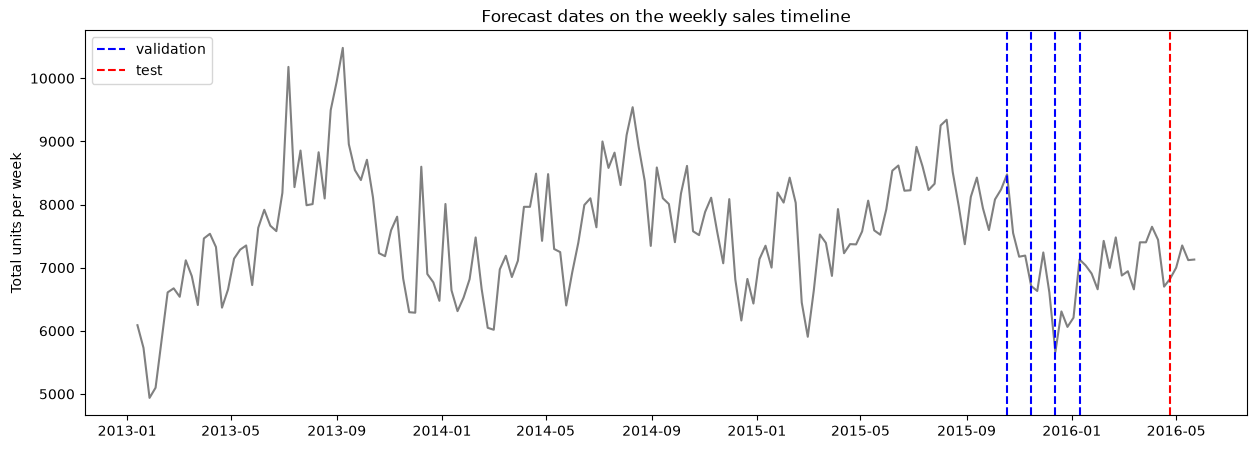

In [5]:
## total weekly sales with a dashed line on every forecast date
total = data.sum()                          # total weekly sales of all products
colors = {'validation': 'blue', 'test': 'red'}

plt.figure(figsize=(15,5))                  # Set Canvas size
plt.plot(total.index, total.values, color='grey')
for i in range(len(split)):                 # one dashed line per forecast date
    plt.axvline(split['forecast_date'][i], color=colors[split['role'][i]], linestyle='dashed')
for i in colors:                            # legend entries
    plt.plot([], [], color=colors[i], linestyle='dashed', label=i)
plt.legend()
plt.title("Forecast dates on the weekly sales timeline")
plt.ylabel("Total units per week")
plt.show()

### Insights :-
- The **4** validation dates forecast the weeks from **25 Oct 2015** to **7 Feb 2016**, without overlap.
- Every next date can use more history : **145** weeks at the first date, **157** at the last one.
- The test date forecasts **1 May** to **22 May 2016**, the last **4** weeks of the data, which nothing else uses.

# 5 . Baseline Models :-

A baseline is the simplest possible forecast, without any machine learning. A model is only worth using if it beats the baselines on the same dates, products and weeks.

- **( a ) . Last Week Naive :** each of the next 4 weeks sells the same as the last known week.
- **( b ) . Seasonal Naive :** each of the next 4 weeks sells the same as the same week **52** weeks before.

In [6]:
## one row per product, validation date and week ahead (h), with the actual sales of that week
fc = []
for origin in VALID_DATES:
    t = weeks.get_loc(origin)               # position of the forecast date
    for h in range(1, H + 1):
        fc.append(pd.DataFrame({'item_id': items, 'origin': origin, 'h': h,
                                'target_week': weeks[t + h],
                                'actual': data.values[:, t + h],
                                'y_pr_last': data.values[:, t],               # ( a ) last known week
                                'y_pr_snaive': data.values[:, t + h - 52]}))  # ( b ) same week last year
fc = pd.concat(fc, ignore_index=True)

print("Forecasts per baseline : ", fc.shape[0], " (4 dates x 100 products x 4 weeks)")
fc[(fc['item_id'] == 'FOODS_1_004') & (fc['origin'] == VALID_DATES[0])]     # one product at the first date

Forecasts per baseline :  1600  (4 dates x 100 products x 4 weeks)


,item_id,origin,h,target_week,actual,y_pr_last,y_pr_snaive
0,FOODS_1_004,2015-10-18,1,2015-10-25,42.0,40.0,13.0
100,FOODS_1_004,2015-10-18,2,2015-11-01,51.0,40.0,80.0
200,FOODS_1_004,2015-10-18,3,2015-11-08,34.0,40.0,75.0
300,FOODS_1_004,2015-10-18,4,2015-11-15,23.0,40.0,72.0


### Insights :-
- Each baseline gives **1,600** forecasts : 4 dates x 100 products x 4 weeks.
- **FOODS_1_004** sold **40** units in the week ending 18 Oct 2015, so Last Week Naive forecasts **40** for each of the next 4 weeks.
- Seasonal Naive forecasts **13, 80, 75** and **72**, the sales of the same weeks in 2014.
- The actual sales were **42, 51, 34** and **23**, so Last Week Naive is much closer for this product.

# 6 . Evaluation :-

The error of a forecast is **actual - forecast**.
- **MAE :** average absolute error, in units.
- **RMSE :** square root of the average squared error, in units. Big misses count more.
- **WAPE :** total absolute error divided by total actual sales.
- **Bias :** average of forecast - actual. Positive means the forecasts are too high.

**RMSSE (the main score) :** an error of 9 units can be good for a big product and bad for a small one. So each product's RMSE is divided by its **normal weekly change** : how much its sales usually move from one week to the next, from its first sale up to the forecast date.
- **RMSSE below 1 :** the error is smaller than a normal weekly change
- **Macro RMSSE :** the average RMSSE of the 100 products, so every product counts the same

MAPE (divides by the actual sales) cannot be used, because some weeks have zero sales.

In [7]:
## normal weekly change of every product, from its first sale up to each forecast date
first = np.searchsorted(weeks.values, first_sale_date.values)            # first sales week of each product

scales = []
for origin in VALID_DATES:
    t = weeks.get_loc(origin)
    for i in range(len(items)):
        change = np.diff(data.values[i, first[i]:t + 1])                  # weekly changes up to the forecast date
        scales.append({'item_id': items[i], 'origin': origin, 'scale_sq': np.mean(change ** 2)})
scales = pd.DataFrame(scales)
fc = fc.merge(scales, on=['item_id', 'origin'], how='left', validate='many_to_one')

scales['normal_change'] = np.sqrt(scales['scale_sq'])                     # typical weekly change in units
scales[scales['origin'] == VALID_DATES[0]].sort_values('normal_change').iloc[[0, 49, 99]].round(2)   # smallest, middle, largest

,item_id,origin,scale_sq,normal_change
53,HOUSEHOLD_1_071,2015-10-18,35.00,5.92
55,HOUSEHOLD_1_096,2015-10-18,388.87,19.72
15,FOODS_3_090,2015-10-18,60025.76,245.00


### Insights :-
- The normal weekly change goes from about **5.92** units (**HOUSEHOLD_1_071**) to **245.00** units (**FOODS_3_090**), with **19.72** in the middle.
- So an error of 20 units is very big for HOUSEHOLD_1_071 but very small for FOODS_3_090. RMSSE divides each product's error by its own normal change, so both products are judged fairly.

In [8]:
## function that scores the forecasts in column 'pred' against 'actual'
def evaluate(fc, pred):
    error = fc['actual'] - fc[pred]
    item = pd.DataFrame({'item_id': fc['item_id'], 'sq': error ** 2, 'scale_sq': fc['scale_sq']}).groupby('item_id').mean()
    rmsse = np.sqrt(item['sq'] / item['scale_sq'].where(item['scale_sq'] > 0))       # one value per product
    return {'Macro RMSSE': rmsse.mean(), 'MAE': error.abs().mean(), 'RMSE': np.sqrt((error ** 2).mean()),
            'WAPE': error.abs().sum() / fc['actual'].sum(), 'Bias': -error.mean()}

## ( i ) . Worked Example on One Product :-

**FOODS_1_004** at the first validation date (18 Oct 2015), scored with both baselines.

In [9]:
## errors and scores of both baselines for one product at the first validation date
example = fc[(fc['item_id'] == 'FOODS_1_004') & (fc['origin'] == VALID_DATES[0])]

print("Actual sales             : ", example['actual'].tolist())
print("Last Week Naive errors   : ", (example['actual'] - example['y_pr_last']).tolist())
print("Seasonal Naive errors    : ", (example['actual'] - example['y_pr_snaive']).tolist())
print("Normal weekly change     : ", round(np.sqrt(example['scale_sq'].iloc[0]), 1))

pd.DataFrame([{'Model': 'Last Week Naive', **evaluate(example, 'y_pr_last')},
              {'Model': 'Seasonal Naive', **evaluate(example, 'y_pr_snaive')}]).round(3)

Actual sales             :  [42.0, 51.0, 34.0, 23.0]
Last Week Naive errors   :  [2.0, 11.0, -6.0, -17.0]
Seasonal Naive errors    :  [29.0, -29.0, -41.0, -49.0]
Normal weekly change     :  39.4


,Model,Macro RMSSE,MAE,RMSE,WAPE,Bias
0,Last Week Naive,0.269,9.0,10.607,0.240,2.5
1,Seasonal Naive,0.963,37.0,37.961,0.987,22.5


### Insights :-
- Last Week Naive is off by **2, 11, -6** and **-17** units, so its MAE is **9** units and its RMSE **10.6** units.
- This product normally moves by **39.4** units a week, so the RMSSE is 10.6 / 39.4 = **0.269** : the error is about a quarter of a normal weekly change.
- Seasonal Naive is off by **29, -29, -41** and **-49** units (RMSE **37.96**), almost a full weekly change : RMSSE **0.963**.
- The Macro RMSSE in the next step is this same calculation, averaged over all **100** products.

## ( ii ) . Baseline Scores :-

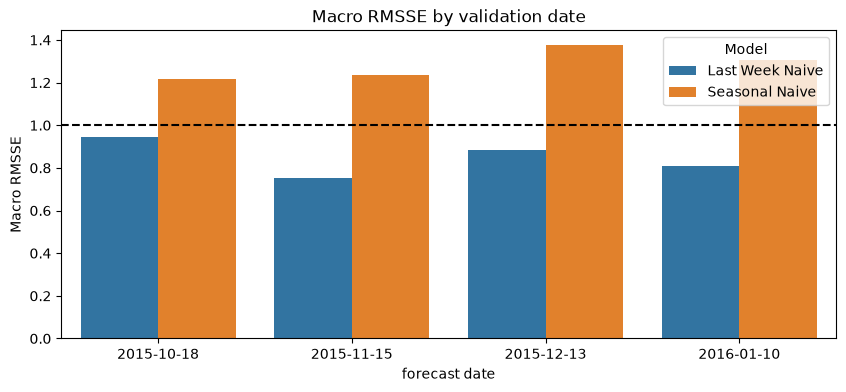

In [10]:
## score both baselines on each validation date
scores = []
for origin in VALID_DATES:                    # score each validation date separately
    part = fc[fc['origin'] == origin]
    scores.append({'Model': 'Last Week Naive', 'origin': origin, **evaluate(part, 'y_pr_last')})
    scores.append({'Model': 'Seasonal Naive', 'origin': origin, **evaluate(part, 'y_pr_snaive')})
scores = pd.DataFrame(scores)

plt.figure(figsize=(10,4))                  # Set Canvas size
sns.barplot(x=scores['origin'].dt.date, y='Macro RMSSE', hue='Model', data=scores)
plt.axhline(1, color='black', linestyle='dashed')
plt.title("Macro RMSSE by validation date")
plt.xlabel("forecast date")
plt.show()

In [11]:
## average scores of both baselines over the 4 validation dates
Results = scores.groupby('Model')[['Macro RMSSE', 'MAE', 'RMSE', 'WAPE', 'Bias']].mean().reset_index()
Results['RMSSE std'] = scores.groupby('Model')['Macro RMSSE'].std().values         # spread over the 4 dates
Results.round(4)

,Model,Macro RMSSE,MAE,RMSE,WAPE,Bias,RMSSE std
0,Last Week Naive,0.8478,20.5175,39.1056,0.3021,2.1400,0.0840
1,Seasonal Naive,1.2838,29.5312,45.2285,0.4365,6.3062,0.0725


### Insights :-
- **Last Week Naive** is better at every validation date and on average : Macro RMSSE **0.8478** against **1.2838** for Seasonal Naive.
- Seasonal Naive has a Macro RMSSE above **1**, so its errors are bigger than a normal weekly change.
- Last Week Naive is also better in MAE (**20.52** against **29.53**) and WAPE (**30.2 %** against **43.7 %**).
- The Macro RMSSE moves by about **0.08** (std) from one date to another, so a small difference between two models should be read with care.

# 7 . Feature Engineering :-

Each row of the feature table is **one product, one forecast date t and one week ahead h**. The value to predict (`target`) is the sales of week **t + h**.

**Rule for every feature :** it uses only the weeks up to **t**. The calendar of week **t + h** (month, SNAP days, event days) is allowed, because it is known in advance.

The table is **not** split into train and test files. Each row has its forecast date (`origin`) and its target week (`target_week`), so the models pick them by date :
- **train :** the rows whose `target_week` is on or before the forecast date
- **validation / test :** the rows whose `origin` is the forecast date

## ( i ) . One Row by Hand :-

**FOODS_1_004** at the first validation date (**18 Oct 2015**), forecasting **1** week ahead. The weeks it may use end on 18 Oct 2015, and the target is the week ending **25 Oct 2015**.

In [12]:
## the weeks of one product around the first validation date, and its features worked out by hand
t = VALID_DATES[0]
one = full_data[(full_data['item_id'] == 'FOODS_1_004') & (full_data['week'] > t - pd.Timedelta(weeks=4))
                & (full_data['week'] <= t + pd.Timedelta(weeks=1))][['week', 'sales', 'price', 'snap_days', 'event_days']]

print("lag_1 (week of 18 Oct)           : ", one['sales'].iloc[3])
print("lag_2 to lag_4 (the 3 weeks before) : ", one['sales'].iloc[2], one['sales'].iloc[1], one['sales'].iloc[0])
print("roll_mean_4 (mean of those 4 weeks) : ", one['sales'].iloc[:4].mean())
print("target (week of 25 Oct)          : ", one['sales'].iloc[4])
one

lag_1 (week of 18 Oct)           :  40
lag_2 to lag_4 (the 3 weeks before) :  46 66 48
roll_mean_4 (mean of those 4 weeks) :  50.0
target (week of 25 Oct)          :  42


,week,sales,price,snap_days,event_days
141,2015-09-27,48,1.96,0,1
142,2015-10-04,66,1.96,4,0
143,2015-10-11,46,1.96,6,0
144,2015-10-18,40,1.96,0,1
145,2015-10-25,42,1.96,0,0


### Insights :-
- On 18 Oct 2015 the last 4 known weeks sold **48, 66, 46** and **40** units. So lag_1 = **40** (the week of 18 Oct) and lag_2 to lag_4 = **46, 66, 48**.
- roll_mean_4 is their average, **50.0** units.
- The target is the sales of the next week (25 Oct 2015) : **42** units. No feature uses that week.

## ( ii ) . Sales History Features :-

All features are first built at the end of every week **t**, one row per product per week.
- **lag_1 to lag_4 :** sales of week t and the 3 weeks before it, the strongest signal in the EDA
- **roll_mean_4, roll_mean_8, roll_mean_13 :** average sales of the last 4, 8 and 13 weeks up to week t

In [13]:
## lags and rolling averages at the end of every week
feat = full_data.sort_values(['item_id', 'week']).reset_index(drop=True)
sales = feat.groupby('item_id')['sales']                                  # sales of each product, in week order

feat['lag_1'] = feat['sales']                                             # week t itself
feat['lag_2'] = sales.shift(1)                                            # 1 week before t
feat['lag_3'] = sales.shift(2)                                            # 2 weeks before t
feat['lag_4'] = sales.shift(3)                                            # 3 weeks before t
for i in [4, 8, 13]:                                                      # average of the last i weeks up to t
    feat['roll_mean_' + str(i)] = sales.transform(lambda s: s.rolling(i).mean())

feat[feat['item_id'] == 'FOODS_1_004'][['week', 'sales', 'lag_1', 'lag_2', 'lag_3', 'lag_4', 'roll_mean_4', 'roll_mean_13']].head(14)

,week,sales,lag_1,lag_2,lag_3,lag_4,roll_mean_4,roll_mean_13
0,2013-01-13,67,67,NaN,NaN,NaN,NaN,NaN
1,2013-01-20,29,29,67.0,NaN,NaN,NaN,NaN
2,2013-01-27,0,0,29.0,67.0,NaN,NaN,NaN
3,2013-02-03,0,0,0.0,29.0,67.0,24.00,NaN
4,2013-02-10,131,131,0.0,0.0,29.0,40.00,NaN
5,2013-02-17,129,129,131.0,0.0,0.0,65.00,NaN
6,2013-02-24,107,107,129.0,131.0,0.0,91.75,NaN
7,2013-03-03,115,115,107.0,129.0,131.0,120.50,NaN
8,2013-03-10,146,146,115.0,107.0,129.0,124.25,NaN
9,2013-03-17,92,92,146.0,115.0,107.0,115.00,NaN


### Insights :-
- Each lag is the sales column moved down by one more week, inside each product, so a product never gets another product's sales.
- The first weeks are empty because there are not enough earlier weeks : roll_mean_13 is first available in the 13th week (**7 Apr 2013**).

## ( iii ) . Price Features :-

- **price :** price in week t
- **price_change :** change against the week before (0.10 means 10 % more expensive)
- **price_ratio_13 :** price divided by the average price of the last 13 weeks (below 1 means cheaper than usual)
- **price_missing :** 1 if the week had no price and it was filled from earlier weeks

Empty prices stay empty, they are never filled from later weeks.

In [14]:
## price features at the end of every week
price = feat.groupby('item_id')['price']                                  # price of each product, in week order

feat['price_change'] = feat['price'] / price.shift(1) - 1                 # change against the week before
feat['price_ratio_13'] = feat['price'] / price.transform(lambda s: s.rolling(13).mean())   # against the 13-week average

feat[['price', 'price_change', 'price_ratio_13']].describe().round(3)

,price,price_change,price_ratio_13
count,17410.000,17310.000,16210.000
mean,1.970,0.000,1.001
std,1.291,0.010,0.020
min,0.780,-0.213,0.745
25%,0.980,0.000,1.000
50%,1.580,0.000,1.000
75%,2.500,0.000,1.000
max,7.970,0.245,1.309


### Insights :-
- Prices rarely change : in at least half of the weeks `price_change` is **0** (the 25 % and 75 % values are both 0).
- When a price changes, it moves between **-21.3 %** and **+24.5 %** in one week.
- `price_ratio_13` stays close to **1** (std **0.020**), from **0.745** to **1.309**.
- `price_ratio_13` has fewer values (**16,210**) than `price` (**17,410**), because it needs 13 weeks of prices.

## ( iv ) . Category and Department :-

One 0/1 column for each category and each department.

In [15]:
## category and department as 0/1 columns
dummies = pd.get_dummies(feat[['cat_id', 'dept_id']]).astype(int)        # one column per category and department
feat = pd.concat([feat, dummies], axis=1)

dummies.sum() / 176                                                       # products in each column (176 weeks each)

cat_id_FOODS           50.0
cat_id_HOUSEHOLD       50.0
dept_id_FOODS_1         7.0
dept_id_FOODS_2         5.0
dept_id_FOODS_3        38.0
dept_id_HOUSEHOLD_1    49.0
dept_id_HOUSEHOLD_2     1.0
dtype: float64

### Insights :-
- **7** new 0/1 columns : **2** categories and **5** departments.
- They hold the same counts as the EDA : **50** FOODS and **50** HOUSEHOLD products, **49** in HOUSEHOLD_1 and **38** in FOODS_3.

## ( v ) . Forecast Week Calendar and Target :-

For each week ahead **h = 1 to 4**, every row gets :
- **target_week, target :** the week t + h and its sales
- **month, week_of_year, snap_days, event_days :** the calendar of week t + h, known in advance
- **same_week_last_year :** sales of week t + h - 52, the Seasonal Naive forecast as a feature

Rows are kept from week **13** onwards (so the 13-week averages are complete) and only when the target week is inside the data.

In [16]:
## one copy of the weekly features for every week ahead, with the calendar and sales of the target week
history = ['lag_1', 'lag_2', 'lag_3', 'lag_4', 'roll_mean_4', 'roll_mean_8', 'roll_mean_13',
           'price', 'price_change', 'price_ratio_13', 'price_missing'] + list(dummies.columns)

rows = []
for h in range(1, H + 1):
    part = feat[['item_id', 'cat_id', 'week'] + history].rename(columns={'week': 'origin'})
    part.insert(3, 'h', h)
    part['target_week'] = part['origin'] + pd.Timedelta(weeks=h)
    part['month'] = part['target_week'].dt.month                          # calendar of the target week
    part['week_of_year'] = part['target_week'].dt.isocalendar().week.astype(int)
    part['snap_days'] = feat.groupby('item_id')['snap_days'].shift(-h)    # known in advance
    part['event_days'] = feat.groupby('item_id')['event_days'].shift(-h)  # known in advance
    part['same_week_last_year'] = sales.shift(52 - h)                     # week t + h - 52
    part['target'] = sales.shift(-h)                                      # sales of week t + h
    rows.append(part)

features = pd.concat(rows, ignore_index=True)
features = features[features['roll_mean_13'].notnull() & features['target'].notnull()].reset_index(drop=True)

print("Feature table shape : ", features.shape)
print("Forecast dates      : ", features['origin'].min().date(), " to ", features['origin'].max().date())

Feature table shape :  (64600, 29)
Forecast dates      :  2013-04-07  to  2016-05-15


### Insights :-
- The feature table has **64,600** rows and **29** columns.
- Forecast dates run from **7 Apr 2013** (the 13th week) to **15 May 2016**. Later dates are left out, because their target week would be after the last week of the data.

## ( vi ) . Check the Row by Hand and Save :-

In [17]:
## the row of FOODS_1_004 on 18 Oct 2015, 1 week ahead, as built by the code
features[(features['item_id'] == 'FOODS_1_004') & (features['origin'] == VALID_DATES[0]) & (features['h'] == 1)].T

,132
item_id,FOODS_1_004
cat_id,FOODS
origin,2015-10-18 00:00:00
h,1
lag_1,40
lag_2,46.0
lag_3,66.0
lag_4,48.0
roll_mean_4,50.0
roll_mean_8,55.625


In [18]:
## how strongly each feature moves with the target (all rows before the first validation date)
features[features['target_week'] <= VALID_DATES[0]].drop(columns=['item_id', 'cat_id', 'origin', 'target_week']).corr(
    )['target'].drop('target').sort_values(ascending=False).round(3)

lag_1                  0.821
roll_mean_4            0.816
roll_mean_8            0.807
roll_mean_13           0.805
lag_2                  0.781
lag_3                  0.751
lag_4                  0.729
same_week_last_year    0.702
cat_id_FOODS           0.501
dept_id_FOODS_3        0.495
dept_id_FOODS_2        0.053
snap_days              0.031
month                  0.023
week_of_year           0.021
price                  0.008
h                      0.001
dept_id_FOODS_1       -0.005
event_days            -0.013
price_change          -0.023
price_missing         -0.056
dept_id_HOUSEHOLD_2   -0.069
price_ratio_13        -0.082
dept_id_HOUSEHOLD_1   -0.487
cat_id_HOUSEHOLD      -0.501
Name: target, dtype: float64

### Insights :-
- The row built by the code matches the row by hand : lag_1 **40**, lag_2 to lag_4 **46, 66, 48**, roll_mean_4 **50.0**, target **42**.
- The strongest features are recent sales : lag_1 **0.821** and roll_mean_4 **0.816**, the other lags and averages **0.729** to **0.807**.
- `same_week_last_year` is lower (**0.702**), as in the EDA.
- Category matters (FOODS **0.501**, HOUSEHOLD **-0.501**), because FOODS products sell more.
- Calendar and price columns are close to **0** (snap_days **0.031**, price_change **-0.023**). Correlation only measures a straight-line link across all products, so these can still help a model inside a product or a category. The models will tell.
- Only rows whose target week is before the first validation date are used here, so the validation and test weeks are not looked at.

In [19]:
## save the feature table
features.to_parquet(DATA_DIR + 'features.parquet', index=False)
print("Saved : ", DATA_DIR + 'features.parquet')

Saved :  ../data/prepared/features.parquet


# ----- CONCLUSION -----

- The split is fixed : models learn from the weeks up to each forecast date (**train**), are compared on the **4** validation dates, and the test date (**24 Apr 2016**) is used only once.
- The main score is **Macro RMSSE**, because the products sell on very different scales (normal weekly change from about **6** to **245** units) and some weeks have zero sales.
- **Last Week Naive** is the stronger baseline, with a Macro RMSSE of **0.8478**. This is the score every model has to beat.
- **Seasonal Naive** is much weaker (**1.2838**), which matches the EDA : sales depend strongly on the last week and only weakly on the same week last year.
- The feature table `data/prepared/features.parquet` has **64,600** rows and **29** columns, built only from the weeks up to each forecast date plus the known calendar of the target week.
- Recent sales are the strongest features (lag_1 **0.821**). Calendar and price features are weak on their own, so the models will show whether they help.